# 03 · Independent Validation, Interpretation & Verdict

This notebook takes the role of an **independent model-validation function**. It uses the **untouched 30% hold-out** (6,000 loans) and challenges the selected model across the following areas:

| § | Area | Question |
|---|---|---|
| 1 | Replication | Can the model be rebuilt independently and give identical PDs? |
| 2 | Discrimination | Does it rank-order risk on unseen data, and does performance hold up out of sample? |
| 3 | Calibration | Are the PD levels accurate, overall and by grade? |
| 4 | Stability | Are the score and feature distributions stable? |
| 5 | Segments | Does it work across sub-populations, including data-quality segments? |
| 6 | Robustness | Are the coefficients stable? What happens with leakage, dropped variables or shocked inputs? |
| 7 | Benchmarking | Is the challenger materially better? |
| 8 | Business | How would it be used: rating grades, cut-offs, expected loss? |
| 9 | Model risk | Limitations and their materiality |
| 10 | **Verdict** | Is it suitable for production use? |

The checks are implemented in `pd_model.validation.validate`; `scripts/validate.py` runs them all and writes `reports/validation/`. The validator loads the **saved artifacts** (`preprocessor.joblib` + `model.joblib`, hash-checked against `metadata.json`), i.e. exactly what the service deploys.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression

from pd_model.config import load_config
from pd_model.data.loading import load_raw, load_split
from pd_model.features.preprocessing import output_sources
from pd_model.models.training import load_artifacts
from pd_model.validation.metrics import gini
from pd_model.validation import validate as V

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

cfg = load_config()
TARGET, SEED = cfg.target, cfg.seed
train, test = load_split(cfg.paths.processed_dir)
preprocessor, model, meta = load_artifacts(cfg)           # sha256-verified
bundle = joblib.load(cfg.paths.candidates)
oof = pd.read_parquet(cfg.paths.oof_predictions)
v = V.ValidationData.build(train, test, preprocessor, bundle["models"], bundle["selected"], bundle["challenger"], cfg, oof)
SEL, CHAL, COLS = v.selected, v.challenger, v.model_columns
y_tr, y_te, pd_sel = v.y_train, v.y_test, v.pd_test
assert np.allclose(model.predict_proba(v.Xp_test)[:, 1], pd_sel)   # saved model == bundle's selected model
print(f"selected = {SEL} | challenger = {CHAL} | inputs = {COLS}")
print(f"test n = {len(test):,}, defaults = {y_te.sum():,}")

selected = B_logreg_parsimonious | challenger = D_lgbm_monotone | inputs = ['credit_utilization', 'past_due_30', 'past_due_60', 'past_due_90', 'past_default', 'dti', 'region_risk_1', 'region_risk_2']
test n = 6,000, defaults = 944


## 1. Replication
The validator re-estimates the selected specification independently, using **statsmodels maximum likelihood** instead of the developer's sklearn pipeline, on the same training data. The 2 must agree.

In [2]:
rep, rep_summary = V.replication(v)
rep_summary

{'max_abs_pd_diff': 0.0005110586898475766,
 'mean_abs_pd_diff': 2.4342646457218843e-05,
 'gini_dev': 0.4182826076753914,
 'gini_validator': 0.4182867980315381,
 'auc_dev': 0.7091413038376957,
 'auc_validator': 0.7091433990157691}

✅ **Replication passed.** The validator's independent MLE fit reproduces the developer's PDs to within 0.001 (the residual comes from sklearn's near-zero L2 penalty) and gives an identical test Gini.

## 2. Discrimination
Both measures are reported: **AUC** (probability that a random defaulter gets a higher PD than a random non-defaulter, 0.5 = random) and **Gini** = 2·AUC − 1 (0 = random), the credit-risk convention. They rank models identically; the industry benchmarks and drop tolerances below are stated in Gini.

In [3]:
V.discrimination(v)

,Train Gini,CV Gini (OOF),Test Gini,Train AUC,CV AUC (OOF),Test AUC,Test KS,Train→Test drop,Rel. drop %,Train→Test drop (AUC)
B_logreg_parsimonious,0.4418,0.4401,0.4183,0.7209,0.7200,0.7091,0.3140,0.0235,5.3221,0.0118
A_logreg_all,0.4469,0.4408,0.4180,0.7234,0.7204,0.7090,0.3207,0.0288,6.4498,0.0144
E_lgbm_free,0.4623,0.4336,0.4171,0.7312,0.7168,0.7085,0.3226,0.0452,9.7849,0.0226
G_xgb_free,0.4767,0.4329,0.4154,0.7384,0.7164,0.7077,0.3215,0.0613,12.8556,0.0306
D_lgbm_monotone,0.4569,0.4344,0.4153,0.7284,0.7172,0.7076,0.3187,0.0416,9.1097,0.0208
F_xgb_monotone,0.4751,0.4346,0.4152,0.7375,0.7173,0.7076,0.3171,0.0599,12.6021,0.0299
H_random_forest,0.4850,0.4204,0.4076,0.7425,0.7102,0.7038,0.3169,0.0774,15.9654,0.0387
C_woe_scorecard,0.4219,0.4155,0.3883,0.7110,0.7077,0.6942,0.2968,0.0336,7.9602,0.0168


In [4]:
ci = V.discrimination_ci(v, cfg.validation["n_bootstrap"], SEED)
print(f"Selected model, test Gini = {ci['gini']:.4f}  (bootstrap 95% CI {ci['gini_ci'][0]:.4f} – {ci['gini_ci'][1]:.4f})")
print(f"Selected model, test AUC  = {ci['auc']:.4f}  (bootstrap 95% CI {ci['auc_ci'][0]:.4f} – {ci['auc_ci'][1]:.4f})")
print(f"Selected model, test KS   = {ci['ks']:.4f}  (bootstrap 95% CI {ci['ks_ci'][0]:.4f} – {ci['ks_ci'][1]:.4f})")

Selected model, test Gini = 0.4183  (bootstrap 95% CI 0.3803 – 0.4577)
Selected model, test AUC  = 0.7091  (bootstrap 95% CI 0.6901 – 0.7288)
Selected model, test KS   = 0.3140  (bootstrap 95% CI 0.2862 – 0.3526)


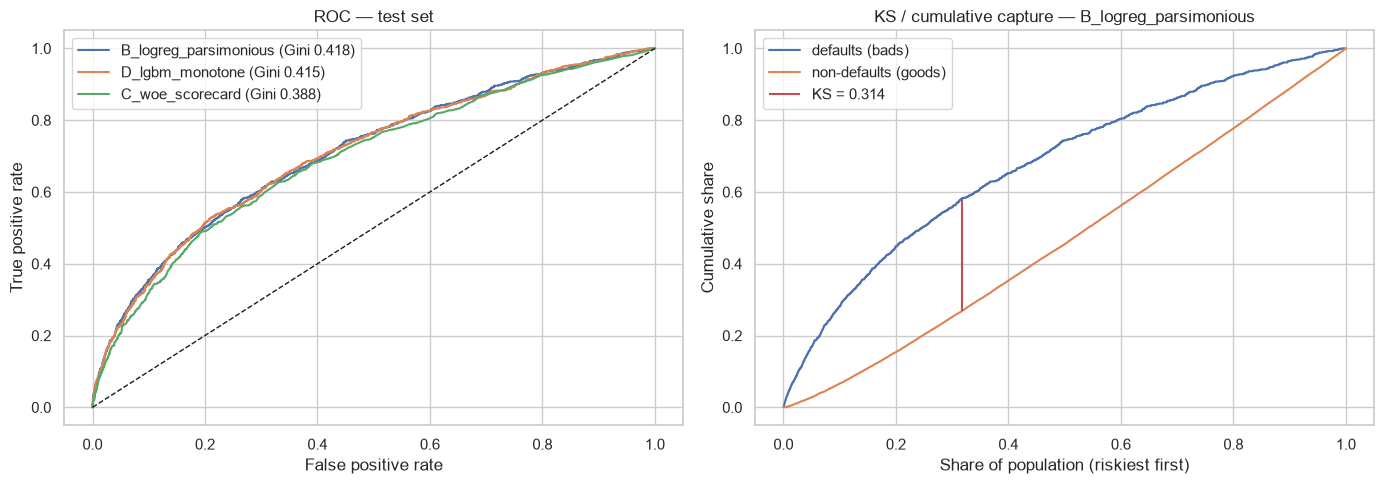

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n in [SEL, CHAL, "C_woe_scorecard"]:
    fpr, tpr, _ = roc_curve(y_te, v.p_test[n])
    axes[0].plot(fpr, tpr, label=f"{n} (Gini {gini(y_te, v.p_test[n]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC — test set", xlabel="False positive rate", ylabel="True positive rate"); axes[0].legend()

order = np.argsort(-pd_sel)
cum_bad = np.cumsum(y_te.values[order]) / y_te.sum()
cum_good = np.cumsum(1 - y_te.values[order]) / (1 - y_te).sum()
pop = np.arange(1, len(order) + 1) / len(order)
axes[1].plot(pop, cum_bad, label="defaults (bads)"); axes[1].plot(pop, cum_good, label="non-defaults (goods)")
i = np.argmax(cum_bad - cum_good)
axes[1].vlines(pop[i], cum_good[i], cum_bad[i], colors="r", label=f"KS = {cum_bad[i]-cum_good[i]:.3f}")
axes[1].set(title=f"KS / cumulative capture — {SEL}", xlabel="Share of population (riskiest first)",
            ylabel="Cumulative share"); axes[1].legend()
plt.tight_layout(); plt.show()

**Benchmarks for retail PD application models.** Common industry rules of thumb: Gini < 0.30 is weak, 0.30–0.45 is acceptable, 0.45–0.60 is good, and > 0.60 is very strong or suspicious for application data. KS > 0.30 is generally acceptable. Typical validation tolerance for the drop from development to validation: relative Gini drop < 10% is green, 10–20% is amber, > 20% is red.

**Results:**
- **Test Gini 0.418** (95% CI 0.380–0.458), i.e. **AUC 0.709** (CI 0.690–0.729), and **KS 0.314** (CI 0.286–0.353). That is **acceptable** discrimination for an application model, though not strong.
- The development → test drop is **5.3% relative** (0.442 → 0.418), inside the green zone. The CV estimate (0.440) sits inside the test confidence interval, so there is no sign of overfitting.
- On the test set **six of the eight candidates sit within 0.415–0.418 Gini**. Only the random forest (0.408) and the WoE scorecard (0.388) are clearly weaker. This confirms the CV-based selection.
- The gradient-boosting models lose the most from development to test (9.1–9.8% for LightGBM, **12.6–12.9% for both XGBoost variants and 16.0% for the random forest, amber**). The simple logistic regression loses the least, which is another reason to prefer it.

## 3. Calibration

In [6]:
cal, hl_tbl, binom = V.calibration(v, cfg.validation["n_grades"])
print(f"Defaults observed {cal['defaults']}, expected {cal['expected_defaults']:.1f}, "
      f"z = {cal['citl_z']:.2f}, two-sided p = {cal['citl_p']:.3f}")
print(f"Hosmer–Lemeshow (10 groups): stat = {cal['hosmer_lemeshow']:.2f}, p-value = {cal['hosmer_lemeshow_p']:.3f}")
hl_tbl

Defaults observed 944, expected 941.4, z = 0.10, two-sided p = 0.923
Hosmer–Lemeshow (10 groups): stat = 7.95, p-value = 0.438


,n,observed,expected,mean_pd,observed_dr
bin,,,,,
0,600,33,31.7353,0.0529,0.0550
1,600,39,39.6902,0.0662,0.0650
2,600,57,46.5178,0.0775,0.0950
3,600,56,53.4116,0.0890,0.0933
4,600,57,62.0516,0.1034,0.0950
5,600,86,72.6623,0.1211,0.1433
6,600,90,88.8754,0.1481,0.1500
7,600,103,115.5257,0.1925,0.1717
8,600,157,159.8147,0.2664,0.2617


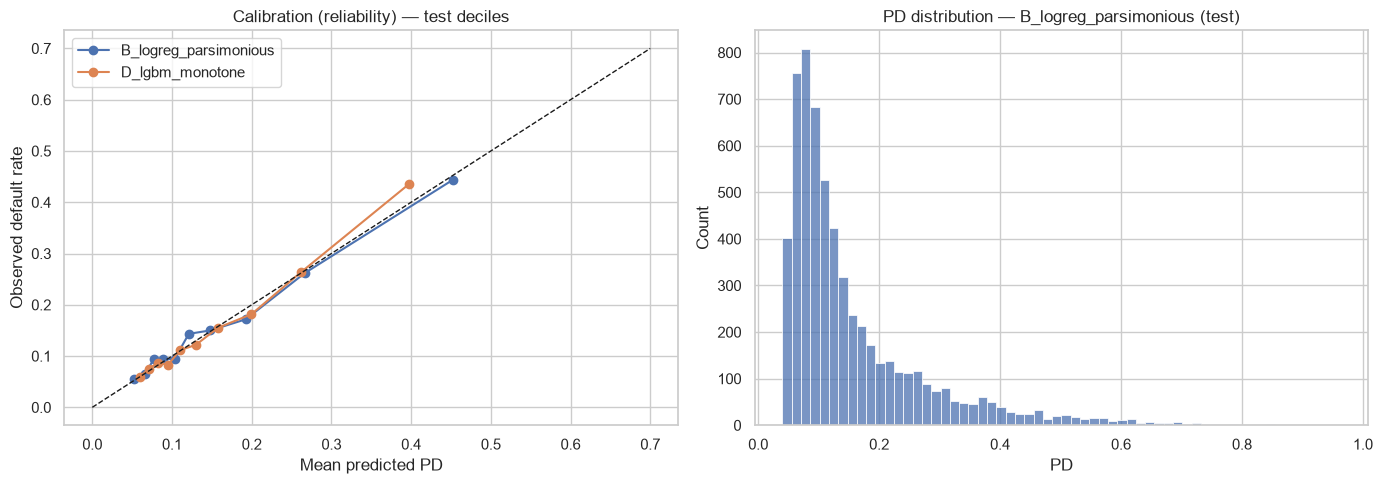

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n in [SEL, CHAL]:
    frac, mean_pred = calibration_curve(y_te, v.p_test[n], n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac, "o-", label=n)
axes[0].plot([0, 0.7], [0, 0.7], "k--", lw=1)
axes[0].set(title="Calibration (reliability) — test deciles", xlabel="Mean predicted PD", ylabel="Observed default rate")
axes[0].legend()
sns.histplot(pd_sel, bins=60, ax=axes[1]); axes[1].set(title=f"PD distribution — {SEL} (test)", xlabel="PD")
plt.tight_layout(); plt.show()

In [8]:
binom

,n,defaults,mean_pd,observed_dr,p_value_underestimation,flag (p<0.05)
grade,,,,,,
1,600,33,0.0529,0.0550,0.4340,False
2,600,39,0.0662,0.0650,0.5685,False
3,600,57,0.0775,0.0950,0.0670,False
4,600,56,0.0890,0.0933,0.3755,False
5,600,57,0.1034,0.0950,0.7693,False
6,600,86,0.1211,0.1433,0.0566,False
7,600,90,0.1481,0.1500,0.4661,False
8,600,103,0.1925,0.1717,0.9128,False
9,600,157,0.2664,0.2617,0.6177,False


The one-sided binomial test asks, per decile grade, whether observed defaults are **significantly above** the predicted PD (i.e. whether the model underestimates risk, the conservative concern for capital and provisioning).

**Results:**
- **Calibration-in-the-large:** mean PD 15.69% vs observed 15.73% (z = 0.10, p = 0.92).
- **Hosmer–Lemeshow:** p = 0.44, so no evidence of miscalibration.
- **Binomial tests:** none of the 10 decile grades significantly underestimates risk.
- Calibration is good across the whole range, from about 5% PD in the best decile to about 45% in the worst.

⚠️ **Caveat:** the split was stratified, so train and test have the same default rate by construction. Good calibration here means the model is internally consistent, **not** that 15.7% is the right long-run default level for the bank's portfolio. That needs a long-run average default rate or later vintages.

## 4. Stability
The data has no time dimension, so the only possible check is train vs test. Because the split is random, a low PSI here is **expected by construction**. It confirms the split is clean but says **nothing about stability over time**, which can only be measured out-of-time or in production monitoring.

In [9]:
score_psi, csi = V.stability(v)
print(f"Score PSI (train → test): {score_psi:.4f}   [<0.10 stable, 0.10–0.25 monitor, >0.25 shift]")
csi

Score PSI (train → test): 0.0016   [<0.10 stable, 0.10–0.25 monitor, >0.25 shift]


,CSI
credit_utilization,0.0030
past_due_30,0.0000
past_due_60,0.0001
past_due_90,0.0000
past_default,0.0000
dti,0.0018
region_risk_1,0.0000
region_risk_2,0.0000


✅ Score PSI = 0.002 and all CSI values < 0.01. That's expected for a random split. Stability **over time** is **not tested** and has to be monitored after go-live.

## 5. Segment analysis

In [10]:
segs = V.segments(v, cfg.preprocessing["income_cap"], cfg.preprocessing["age_placeholder"])
segs

,n,defaults,observed DR,mean PD,PD / DR,p underest.,Gini,AUC
segment,,,,,,,,
block = 1,3870,624,0.1612,0.1570,0.9737,0.2280,0.4129,0.7065
block = 2,2130,320,0.1502,0.1567,1.0433,0.8181,0.4289,0.7145
region_risk = 0,3567,493,0.1382,0.1377,0.9963,0.4727,0.3908,0.6954
region_risk = 1,1805,322,0.1784,0.1797,1.0074,0.5748,0.4608,0.7304
region_risk = 2,628,129,0.2054,0.2005,0.9759,0.3909,0.3726,0.6863
age_band = ≤25,833,127,0.1525,0.1584,1.0388,0.7087,0.4164,0.7082
age_band = 26–35,1583,254,0.1605,0.1629,1.0154,0.6256,0.4181,0.7090
age_band = 36–50,2604,409,0.1571,0.1530,0.9744,0.2829,0.4202,0.7101
age_band = 51–65,883,133,0.1506,0.1565,1.0389,0.7116,0.3984,0.6992


The data-quality segments are especially important: `block = 2` (the corrupted source), `income_reconstructed` (repaired incomes) and `inconsistent_record` (rows breaking logical rules). If the model only worked on clean rows, the data-quality issues would be material.

**Results:**
- Discrimination holds in every segment, with Gini between 0.31 and 0.53. The weakest band is `dti` 0.3–0.5, which is natural because restricting dti removes the strongest driver.
- **Both data blocks perform the same** (Gini 0.41 vs 0.43, PD/DR 0.97 vs 1.04), so the repairs made in `pd_model.data.cleaning` worked.
- Calibration is within ±5% for almost all segments, with 2 exceptions:
  - `inconsistent_record = 1`: observed 22.8% vs predicted 20.0%. This is the **only significant underestimation** (p = 0.026). With 22 segments tested, about one false positive at 5% is expected, but the direction fits the EDA: clients whose DPD counts exceed their number of loans are riskier than the model thinks. This points to the DPD-definition issue rather than random noise, so it becomes a **condition** (confirm the definitions and re-test).
  - `income_reconstructed = 1`: PD/DR 0.88, but not significant (p = 0.15, 53 defaults).
- `age 65+` (n = 65) is too small to judge.

## 6. Robustness and sensitivity

### 6.1 What leakage would have done

In [11]:
flag = load_raw(cfg.paths.raw_data).reset_index(drop=True)["recovery_flag_after_90d"]   # aligned on row_id
tr_l = v.Xp_train[COLS].assign(recovery_flag_after_90d=flag.loc[train.row_id].values)
te_l = v.Xp_test[COLS].assign(recovery_flag_after_90d=flag.loc[test.row_id].values)
m_leak = LogisticRegression(max_iter=3000).fit(tr_l, y_tr)
print(f"Same model + recovery_flag_after_90d: test Gini = {gini(y_te, m_leak.predict_proba(te_l)[:, 1]):.4f} "
      f"(vs {gini(y_te, pd_sel):.4f} without)")

Same model + recovery_flag_after_90d: test Gini = 0.9021 (vs 0.4183 without)


Adding the post-default flag would roughly double the Gini to an implausible level. That performance could never be achieved in production, because the flag doesn't exist at application time. **Excluding it is the single most important decision in the modelling flow.**

### 6.2 Coefficient stability (bootstrap of the training data)

In [12]:
rng = np.random.default_rng(SEED)
Xs_tr = sm.add_constant(v.Xp_train[COLS])
boot = []
for _ in range(300):
    idx = rng.integers(0, len(train), len(train))
    boot.append(sm.Logit(y_tr.values[idx], Xs_tr.iloc[idx]).fit(disp=0).params)
boot = pd.DataFrame(boot)
coef_stab = pd.DataFrame({"estimate": rep.params, "boot mean": boot.mean(), "boot 2.5%": boot.quantile(0.025),
                          "boot 97.5%": boot.quantile(0.975), "share positive": (boot > 0).mean()})
coef_stab["CV of coef"] = boot.std() / boot.mean().abs()
coef_stab

,estimate,boot mean,boot 2.5%,boot 97.5%,share positive,CV of coef
const,-2.0500,-2.0511,-2.1108,-1.9857,0.0000,0.0159
credit_utilization,0.1178,0.1196,0.0774,0.1679,1.0000,0.1969
past_due_30,0.2445,0.2447,0.2000,0.2891,1.0000,0.0915
past_due_60,0.3071,0.3047,0.2608,0.3474,1.0000,0.0737
past_due_90,0.2431,0.2437,0.2037,0.2803,1.0000,0.0810
past_default,0.4655,0.4690,0.4305,0.5021,1.0000,0.0401
dti,0.3961,0.3979,0.3630,0.4391,1.0000,0.0511
region_risk_1,0.3571,0.3558,0.2454,0.4612,1.0000,0.1501
region_risk_2,0.5913,0.5900,0.4503,0.7251,1.0000,0.1245


✅ Every coefficient keeps its sign in 100% of bootstrap samples, and every 95% interval excludes 0. `credit_utilization` is the least precise (coefficient of variation 0.20) but still clearly positive.

### 6.3 Variable importance by removal (test Gini when one driver is dropped and the model refitted)

In [13]:
src = output_sources(COLS, cfg.categorical)
drop = {}
for f in sorted(set(src.values())):                     # region_risk drops both dummies
    keep = [c for c in COLS if src[c] != f]
    m = LogisticRegression(C=1e6, max_iter=3000).fit(v.Xp_train[keep], y_tr)
    drop[f] = gini(y_te, pd_sel) - gini(y_te, m.predict_proba(v.Xp_test[keep])[:, 1])
pd.Series(drop, name="Gini loss when removed").sort_values(ascending=False).to_frame()

,Gini loss when removed
dti,0.0734
past_default,0.0732
past_due_60,0.0362
past_due_30,0.0253
past_due_90,0.0215
region_risk,0.0103
credit_utilization,0.0045


`dti` and `past_default` carry most of the model (each is worth about 0.07 Gini). The delinquency counts add about 0.02–0.04 each, and region and utilisation add about 0.01 or less. The model is **concentrated on 2 drivers**, and `dti` is itself built from income, which is censored at 30k. That is a known weakness: the model can't tell a 30k earner from a 100k earner.

### 6.4 Input shocks: sensitivity of the portfolio mean PD

In [14]:
# Shocks are applied to the RAW inputs and pushed through the saved preprocessor + model, as in production.
shocks = {
    "base": {},
    "DTI +20%": {"dti": lambda s: s * 1.2},
    "utilisation +10pp": {"credit_utilization": lambda s: (s + 0.10).clip(upper=1)},
    "all regions +1 step": {"region_risk": lambda s: (s + 1).clip(upper=2)},
    "+1 30-DPD for everyone": {"past_due_30": lambda s: s + 1},
}
res = {}
for name, sh in shocks.items():
    X_s = test[cfg.raw_features].copy()
    for c, fn in sh.items():
        X_s[c] = fn(X_s[c])
    res[name] = model.predict_proba(preprocessor.transform(X_s))[:, 1].mean()
s = pd.Series(res, name="mean PD").to_frame()
s["Δ vs base (pp)"] = 100 * (s["mean PD"] - s.loc["base", "mean PD"])
s

,mean PD,Δ vs base (pp)
base,0.1569,0.0000
DTI +20%,0.1695,1.2627
utilisation +10pp,0.1648,0.7849
all regions +1 step,0.1918,3.4919
+1 30-DPD for everyone,0.2076,5.0655


The responses are smooth, directionally correct and proportionate. Nothing explodes, which is expected from a logistic model with bounded inputs (DTI is winsorised).

## 7. Benchmarking against the challenger

In [15]:
chal = V.challenger_comparison(v, cfg.validation["n_bootstrap"], SEED)
print(f"Test Gini: challenger {chal['gini_challenger']:.4f} vs selected {chal['gini_selected']:.4f}")
print(f"Δ Gini (challenger − selected) = {chal['delta_gini_mean']:+.4f}, "
      f"95% CI [{chal['delta_gini_ci'][0]:+.4f}, {chal['delta_gini_ci'][1]:+.4f}]")
print(f"Test AUC:  challenger {chal['auc_challenger']:.4f} vs selected {chal['auc_selected']:.4f}, "
      f"Δ AUC = {chal['delta_auc_mean']:+.4f}, 95% CI [{chal['delta_auc_ci'][0]:+.4f}, {chal['delta_auc_ci'][1]:+.4f}]")
print(f"Spearman rank correlation of PDs: {chal['spearman_pd']:.3f}")

Test Gini: challenger 0.4153 vs selected 0.4183
Δ Gini (challenger − selected) = -0.0029, 95% CI [-0.0104, +0.0048]
Test AUC:  challenger 0.7076 vs selected 0.7091, Δ AUC = -0.0014, 95% CI [-0.0052, +0.0024]
Spearman rank correlation of PDs: 0.974


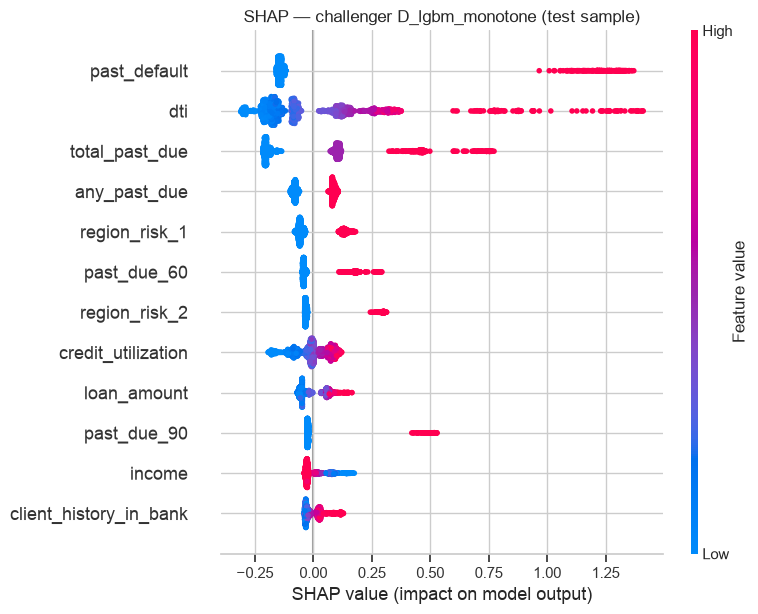

In [16]:
import shap
sample = v.Xp_test.sample(2000, random_state=SEED)
sv = shap.TreeExplainer(v.models[CHAL]).shap_values(sample)
shap.summary_plot(sv, sample, show=False, max_display=12)
plt.title(f"SHAP — challenger {CHAL} (test sample)"); plt.tight_layout(); plt.show()

✅ The challenger is **not better**: Δ Gini −0.003 (Δ AUC −0.0014), and the 95% CI [−0.010, +0.005] includes 0. Its PD ranking correlates 0.97 with the selected model's. The extra complexity of gradient boosting buys nothing on this data.

The challenger independently picks the same drivers, with the same directions, as the selected model. Nothing material is left out of the logistic specification.

## 8. Business interpretation
### 8.1 Rating grades (master scale)

In [17]:
grades = V.grade_table(v, cfg.scorecard["master_scale"])
grades

,n,defaults,mean_PD,observed_DR,share,PD range
grade,,,,,,
A,168,7,0.0471,0.0417,0.0280,0%–5%
B,1455,106,0.0657,0.0729,0.2425,5%–8%
C,1667,177,0.0981,0.1062,0.2778,8%–12%
D,1092,156,0.1460,0.1429,0.1820,12%–18%
E,619,123,0.2126,0.1987,0.1032,18%–25%
F,662,199,0.3121,0.3006,0.1103,25%–40%
G,337,176,0.5245,0.5223,0.0562,40%–100%


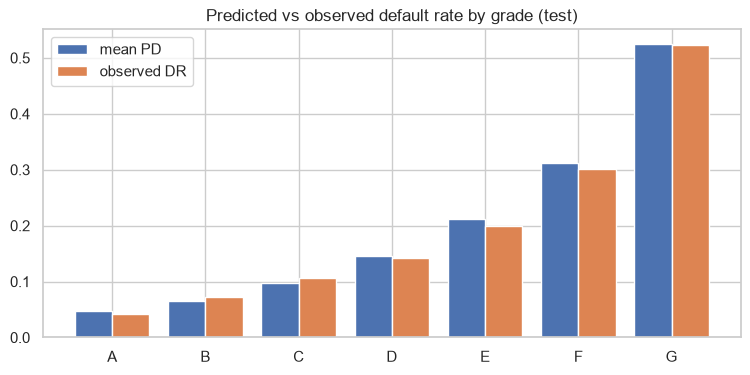

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(grades))
ax.bar(x - 0.2, grades.mean_PD, 0.4, label="mean PD")
ax.bar(x + 0.2, grades.observed_DR, 0.4, label="observed DR")
ax.set_xticks(x); ax.set_xticklabels(grades.index); ax.set_title("Predicted vs observed default rate by grade (test)")
ax.legend(); plt.show()

Observed default rates rise steadily from grade A to G (4.2% → 52.2%), and each grade's mean PD matches its observed DR closely. The scale **rank-orders well**, though grade A is thin (2.8% of clients): the data contains very few truly low-risk borrowers.

### 8.2 Cut-off strategy
For a lender, the model decides **who gets approved**. Below, applicants are approved from the safest PD upwards, and the table shows the trade-off between volume and losses. Expected loss uses the Basel-style EL = PD × LGD × EAD with an **illustrative LGD of 45%** (Basel F-IRB senior unsecured) and EAD = `loan_amount`. The dataset doesn't contain LGD, so all loss figures are indicative only.

In [19]:
cutoff, el = V.cutoff_table(v, cfg.validation["lgd"])
cutoff

,approval rate,PD cut-off,bad rate approved,bad rate reduction,defaults avoided,goods lost,realised loss avoided
0,1.0000,1.0000,0.1573,0.0000,0.0000,0.0000,0.0000
1,0.9500,0.4166,0.1377,0.1247,0.1684,0.0279,0.2591
2,0.9000,0.3184,0.1256,0.2020,0.2818,0.0661,0.4074
3,0.8500,0.2630,0.1167,0.2585,0.3697,0.1090,0.4921
4,0.8000,0.2235,0.1085,0.3101,0.4481,0.1537,0.5791
5,0.7000,0.1670,0.0995,0.3674,0.5572,0.2520,0.6930
6,0.6000,0.1326,0.0911,0.4209,0.6525,0.3528,0.7735


In [20]:
print(f"Portfolio expected loss (model): {el['expected_loss']:,.0f} | realised loss at LGD 45%: {el['realised_loss']:,.0f} "
      f"| ratio {el['ratio']:.3f}")

Portfolio expected loss (model): 6,669,295 | realised loss at LGD 45%: 6,642,667 | ratio 1.004


**Business reading:**
- **Declining the riskiest 10%** (PD > 32%) avoids **28% of defaults** and about **41% of realised losses**, at the cost of 6.6% of good clients. The approved book's bad rate falls from 15.7% to 12.6%.
- **Declining 20%** (PD > 22%) avoids 45% of defaults and about 58% of losses, losing 15% of goods.
- Losses fall faster than default counts because riskier clients also borrow more relative to income (high `dti`).
- Portfolio **expected loss** from the model matches realised loss within **0.4%** (at the assumed LGD), so the PDs are usable for pricing and provisioning inputs, subject to the long-run calibration caveat.
- The PDs also support **risk-based pricing**. Today `interest_rate` has no relation to risk (IV ≈ 0), which means low-risk clients currently subsidise high-risk ones. This is an immediate business opportunity.

Where to set the cut-off is a **business decision**: it trades margin on good clients against credit losses, and needs the bank's LGD, funding cost and risk appetite.

## 9. Model-risk assessment

| # | Risk | Evidence | Materiality | Mitigation / condition |
|---|---|---|---|---|
| R1 | **Target leakage** | `recovery_flag_after_90d` matches target in 95% of rows; with it Gini jumps to 0.90 | **High** if it reaches production | Excluded. Production data contract must **not** feed this field |
| R2 | **Source data quality** | Block 2: 80 loans ×10, 700 low incomes deleted, age = 99 placeholders, duplicate index | **High** (process), Low (model, after repair) | Repaired exactly; both blocks perform equally. **Input validation rules needed in production** (dti = loan/income identity, loan ≤ 80k, age 21–75, income not null) |
| R3 | **Unconfirmed definitions** | DPD buckets not nested; DPD > num_loans; `dti` is really loan-to-income; default definition and horizon not stated | Medium | Confirm with data owner. The only significant segment miscalibration (`inconsistent_record`, p = 0.026) is linked to this |
| R4 | **No out-of-time validation** | No date field; random hold-out only | Medium–High | OOT test on a later vintage before full rollout; monitoring after go-live |
| R5 | **Long-run calibration unknown** | Sample DR 15.7% fixed by stratification; no cycle information | Medium (decisioning) / High (capital, IFRS 9) | Recalibrate the intercept to the bank's long-run default rate; add a margin of conservatism for regulatory use |
| R6 | **Moderate discrimination, concentrated drivers** | Gini 0.42; `dti` and `past_default` dominate; income censored at 30k | Medium | Acceptable for decision support. Look for new data (bureau scores, true income, behavioural data) |
| R7 | **Synthetic-looking data** | Independent features (all \|corr\| < 0.1 except dti-related), implausible age/tenure combinations | Medium (generalisability) | Re-develop / re-validate on real portfolio data before reliance |
| R8 | **Sample selection (through-the-door)** | Only booked loans observed, no rejects | Medium | Reject inference or a policy-aware approach when the model changes approval policy |
| R9 | Model specification | 7 significant (8 inputs, region one-hot encoded), correctly signed, stable, non-collinear drivers; challenger not better; no overfit | **Low** | — |

## 10. Verdict

### Summary of validation results

| Test | Result | Status |
|---|---|---|
| Replication | identical Gini, PDs within 0.001 | ✅ |
| Discrimination | test Gini 0.418 (CI 0.38–0.46) = AUC 0.709 (CI 0.69–0.73), KS 0.314 | ✅ acceptable (moderate) |
| Overfitting | 5% relative Gini drop dev → test | ✅ green |
| Calibration | mean PD 15.69% vs DR 15.73%; HL p = 0.44; no grade underestimated | ✅ |
| Stability | PSI 0.002 (random split only) | ⚠️ not tested over time |
| Segments | Gini 0.31–0.53 everywhere; one significant underestimation (inconsistent records) | ⚠️ minor |
| Robustness | coefficients 100% sign-stable; smooth shock responses | ✅ |
| Benchmark | LightGBM challenger not better (Δ Gini −0.003) | ✅ |
| Conceptual soundness | simple, interpretable, every driver economically sensible | ✅ |
| Data | leakage removed, corruption repaired, but definitions unconfirmed and no time dimension | ⚠️ |

### Conclusion

**The model is CONDITIONALLY SUITABLE for production use as an application-scoring PD model (credit decisioning and risk-based pricing support).**

The model itself is sound. It is simple, transparent, statistically significant in every driver, free of overfitting, well calibrated on hold-out data, and matched by a much more flexible challenger. Its discriminatory power (Gini ≈ 0.42) is moderate, but it reflects the limited information in the data rather than a modelling failure: no technique extracted more.

The remaining risks are in the **data and the validation evidence**, not the model. Before go-live:
1. **Confirm definitions** with the data owner: the default definition and horizon, the DPD bucket semantics, `num_loans`, and `dti`. Re-test the `inconsistent_record` segment afterwards.
2. **Lock the production data contract**: `recovery_flag_after_90d` must be excluded, and input validation rules must catch the block-2 error types.
3. **Out-of-time validation** on the most recent vintage, with the same criteria (Gini drop < 10% relative, PSI < 0.10, binomial tests per grade).
4. **Recalibrate** the intercept to the bank's long-run central-tendency default rate.

After go-live:
- Monthly PSI/CSI monitoring (alert at PSI > 0.10, action at > 0.25).
- Quarterly Gini and calibration backtests (trigger a review if Gini < 0.35 or any grade fails the binomial test).
- Keep the LightGBM challenger running in parallel.
- Annual re-validation.

**Not suitable in its current form for regulatory capital (IRB) or IFRS 9 provisioning**, which additionally require long-run / through-the-cycle calibration, a margin of conservatism, point-in-time forward-looking adjustments and multi-year data, none of which this dataset provides.